# Salary Prediction – Model Training
**Target Variable:** Salary &nbsp;|&nbsp; **Feature:** Experience Years

This notebook loads the data, explores it, trains a regression model, evaluates it and saves the trained model (`model/model.pkl`) which is used by the Streamlit app (`app.py`).

**Importing libraries**

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")

**---------------PART 1: Load and understand the data---------------**

**Load the dataset**

In [2]:
path = "../data/Salary_Data.csv"
if not os.path.exists(path):      # if notebook is run from the project root
    path = "data/Salary_Data.csv"

df_sal = pd.read_csv(path)
df_sal

,Experience Years,Salary
0,1.1,39343
1,1.2,42774
2,1.3,46205
3,1.5,37731
4,2.0,43525
5,2.2,39891
6,2.5,48266
7,2.9,56642
8,3.0,60150
9,3.2,54445


**Number of rows and columns**

In [3]:
df_sal.shape

(40, 2)

**First and last records**

In [4]:
df_sal.head()

,Experience Years,Salary
0,1.1,39343
1,1.2,42774
2,1.3,46205
3,1.5,37731
4,2.0,43525


In [5]:
df_sal.tail()

,Experience Years,Salary
35,9.0,105582
36,9.5,116969
37,9.6,112635
38,10.3,122391
39,10.5,121872


**Column names and data types**

In [6]:
df_sal.info()

<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Experience Years  40 non-null     float64
 1   Salary            40 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 772.0 bytes


**Descriptive statistics**

In [7]:
df_sal.describe()

,Experience Years,Salary
count,40.000000,40.000000
mean,5.152500,74743.625000
std,2.663715,25947.122885
min,1.100000,37731.000000
25%,3.200000,56878.250000
50%,4.600000,64472.500000
75%,6.875000,95023.250000
max,10.500000,122391.000000


we have only 2 columns and both are numerical.
- Experience Years (input / feature): 1.1 to 10.5 years
- Salary (output / target): around 37,000 to 122,000

**---------------PART 2: Data cleaning---------------**

**Missing values**

In [8]:
df_sal.isna().sum()

Experience Years    0
Salary              0
dtype: int64

**Duplicate records**

In [9]:
df_sal.duplicated().sum()

np.int64(0)

**Invalid values (negative or zero)**

In [10]:
print("Experience <= 0 :", (df_sal['Experience Years'] <= 0).sum())
print("Salary <= 0     :", (df_sal['Salary'] <= 0).sum())

Experience <= 0 : 0
Salary <= 0     : 0


No missing values, no duplicates and no invalid values, so the data is already clean and no preprocessing is needed. Both columns are numeric, so no encoding is needed either.

**---------------PART 3: Exploratory analysis---------------**

**Distribution of experience and salary**

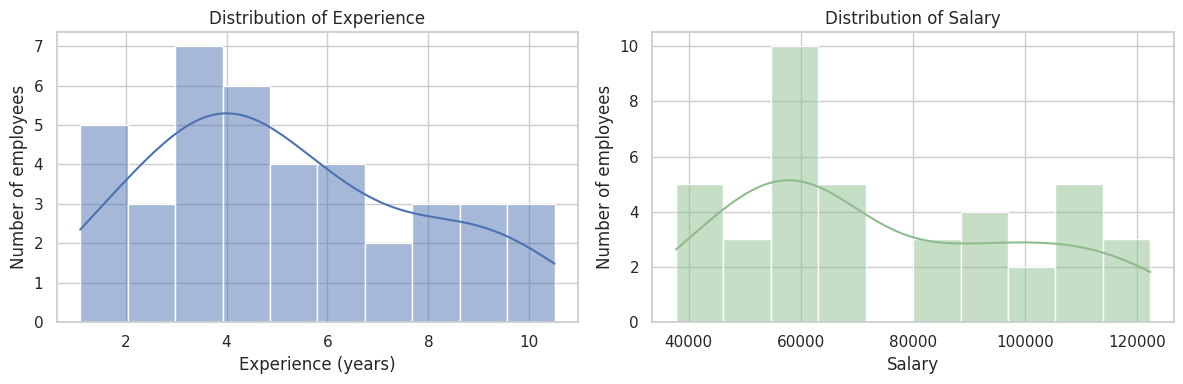

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_sal['Experience Years'], bins=10, kde=True, ax=axes[0])
axes[0].set(title="Distribution of Experience", xlabel="Experience (years)", ylabel="Number of employees")
sns.histplot(df_sal['Salary'], bins=10, kde=True, ax=axes[1], color="darkseagreen")
axes[1].set(title="Distribution of Salary", xlabel="Salary", ylabel="Number of employees")
plt.tight_layout()
plt.show()

**Relationship between experience and salary**

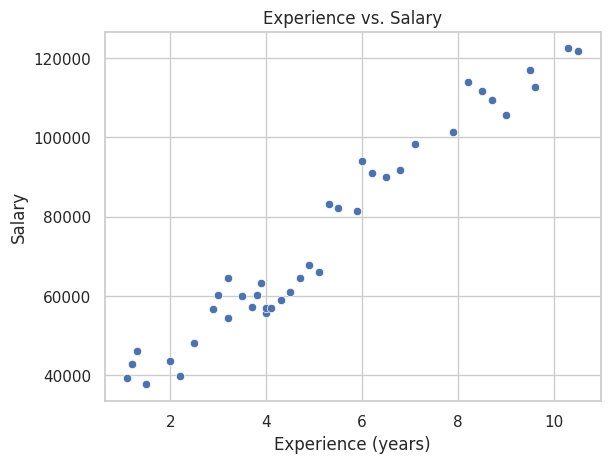

Correlation: 0.9777


In [12]:
sns.scatterplot(data=df_sal, x='Experience Years', y='Salary')
plt.title("Experience vs. Salary")
plt.xlabel("Experience (years)")
plt.ylabel("Salary")
plt.show()

print("Correlation:", round(df_sal['Experience Years'].corr(df_sal['Salary']), 4))

The points follow almost a straight line and the correlation is about **0.98** (very strong positive). So a simple **Linear Regression** is a good choice for this data.

**---------------PART 4: Features, target and train test split---------------**

In [13]:
X = df_sal[['Experience Years']]     # feature (kept as a dataframe, 2D)
y = df_sal['Salary']                 # target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(32, 1) (8, 1)


**---------------PART 5: Train the model---------------**

In [14]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [15]:
print("Intercept   :", round(model.intercept_, 2))
print("Coefficient :", round(model.coef_[0], 2))

Intercept   : 26716.25
Coefficient : 9408.03


The coefficient means that on average **each extra year of experience adds about this much** to the salary.

**---------------PART 6: Evaluate the model---------------**

In [16]:
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE  :", round(mse, 2))
print("RMSE :", round(rmse, 2))
print("MAE  :", round(mae, 2))
print("R2   :", round(r2, 4))

MSE  : 48077731.17
RMSE : 6933.81
MAE  : 6419.91
R2   : 0.9069


**Actual vs predicted (test set)**

In [17]:
pd.DataFrame({'Experience Years': X_test['Experience Years'].values,
              'Actual': y_test.values,
              'Predicted': y_pred.round(0)})

,Experience Years,Actual,Predicted
0,4.5,61111,69052.0
1,4.0,56957,64348.0
2,4.0,55794,64348.0
3,6.0,93940,83164.0
4,2.0,43525,45532.0
5,3.7,57189,61526.0
6,9.6,112635,117033.0
7,6.2,91000,85046.0


**5-fold cross validation** (the dataset has only 40 rows, so one test split of 8 rows can be lucky or unlucky; cross validation gives a more reliable score)

In [18]:
# the csv is sorted by experience, so the folds must be shuffled (otherwise each fold tests on a range the model never saw)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(LinearRegression(), X, y, cv=kf, scoring='r2')
print("R2 of each fold :", cv_scores.round(4))
print("Mean R2         :", round(cv_scores.mean(), 4))

R2 of each fold : [0.9069 0.9887 0.9616 0.95   0.9265]
Mean R2         : 0.9467


**Regression line on the data**

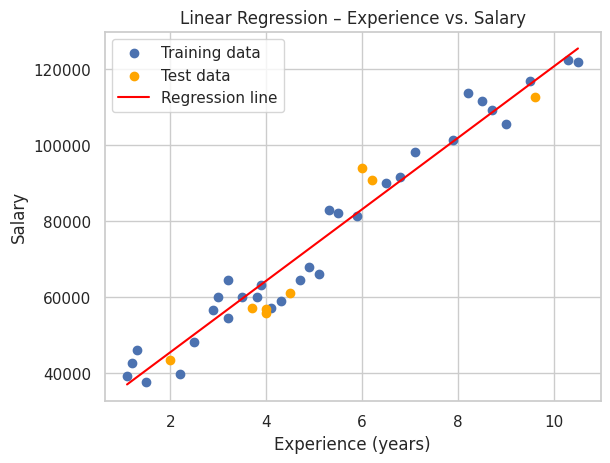

In [19]:
plt.scatter(X_train, y_train, label="Training data")
plt.scatter(X_test, y_test, color="orange", label="Test data")
line_x = pd.DataFrame({'Experience Years': np.linspace(X['Experience Years'].min(), X['Experience Years'].max(), 50)})
plt.plot(line_x, model.predict(line_x), color="red", label="Regression line")
plt.title("Linear Regression – Experience vs. Salary")
plt.xlabel("Experience (years)")
plt.ylabel("Salary")
plt.legend()
plt.show()

- **R2 close to 1** (see output above) means the model explains almost all the variation in salary.
- **MAE** is the average error in salary units, **RMSE** gives more weight to big errors.
- Test set is small (8 rows), so the cross validation score is the more reliable number.

**---------------PART 7: Save the model---------------**

The model is saved with joblib. The Streamlit app loads this file, it does **not** train again. A small json file with the metrics is also saved so the app can show the model performance.

In [20]:
model_dir = "../model" if os.path.exists("../data/Salary_Data.csv") else "model"
os.makedirs(model_dir, exist_ok=True)

joblib.dump(model, f"{model_dir}/model.pkl")

metrics = {
    "model": "Linear Regression",
    "mse": float(mse), "rmse": float(rmse), "mae": float(mae), "r2": float(r2),
    "cv_r2_mean": float(cv_scores.mean()),
    "intercept": float(model.intercept_), "coefficient": float(model.coef_[0]),
    "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
    "min_experience": float(X['Experience Years'].min()),
    "max_experience": float(X['Experience Years'].max()),
}
with open(f"{model_dir}/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved:", os.listdir(model_dir))

Saved: ['metrics.json', 'model.pkl']


**Check: load the saved model and predict**

In [21]:
loaded_model = joblib.load(f"{model_dir}/model.pkl")
test_input = pd.DataFrame({'Experience Years': [5.0]})
print("Predicted salary for 5 years of experience:", round(loaded_model.predict(test_input)[0], 2))

Predicted salary for 5 years of experience: 73756.41


## Conclusion
A **Linear Regression** model was trained on the Salary dataset (40 rows) to predict salary from years of experience. The data was clean, experience and salary are very strongly correlated (about 0.98) and the model reached a high R2 on the test set and in cross validation. The model is saved in `model/model.pkl` and is used by the Streamlit app.

**Limitations:** only one feature (experience) and only 40 rows, so the model cannot account for job role, education, city etc. and it should not be trusted for experience values outside the training range (about 1 to 10.5 years).